In [1]:
import os

import torch
import matplotlib.pyplot as plt

from networks.repair import RepairNetworkLinear

In [2]:
saved_dir = os.getcwd()+'/networks/saved/'

In [3]:
NUM_STATES = 400
RANK = 20
PATHS = [saved_dir+'HBarrier.pt', saved_dir+'LBarrier.pt']
device = torch.device('mps')

model = RepairNetworkLinear(num_states=NUM_STATES, hidden_dim=RANK).to(device)
model.load_state_dict(torch.load(PATHS[0]))
model.eval()

RepairNetworkLinear(
  (repair): Sequential(
    (0): Linear(in_features=400, out_features=20, bias=True)
    (1): ReLU()
    (2): Linear(in_features=20, out_features=400, bias=True)
  )
)

### Weight matrix visualization
Visualizing the encoder weight matrix (W1: RxS) and the decoder weight matrix (W2: SxR) <br>
Where R is the rank of the model and S is the input size (number of states in baseline).

In [4]:
W1 = model.repair[0].weight.data.cpu()
W2 = model.repair[2].weight.data.cpu()

Text(0.5, 0.98, 'Encoder basis vectors (reshaped to grid)')

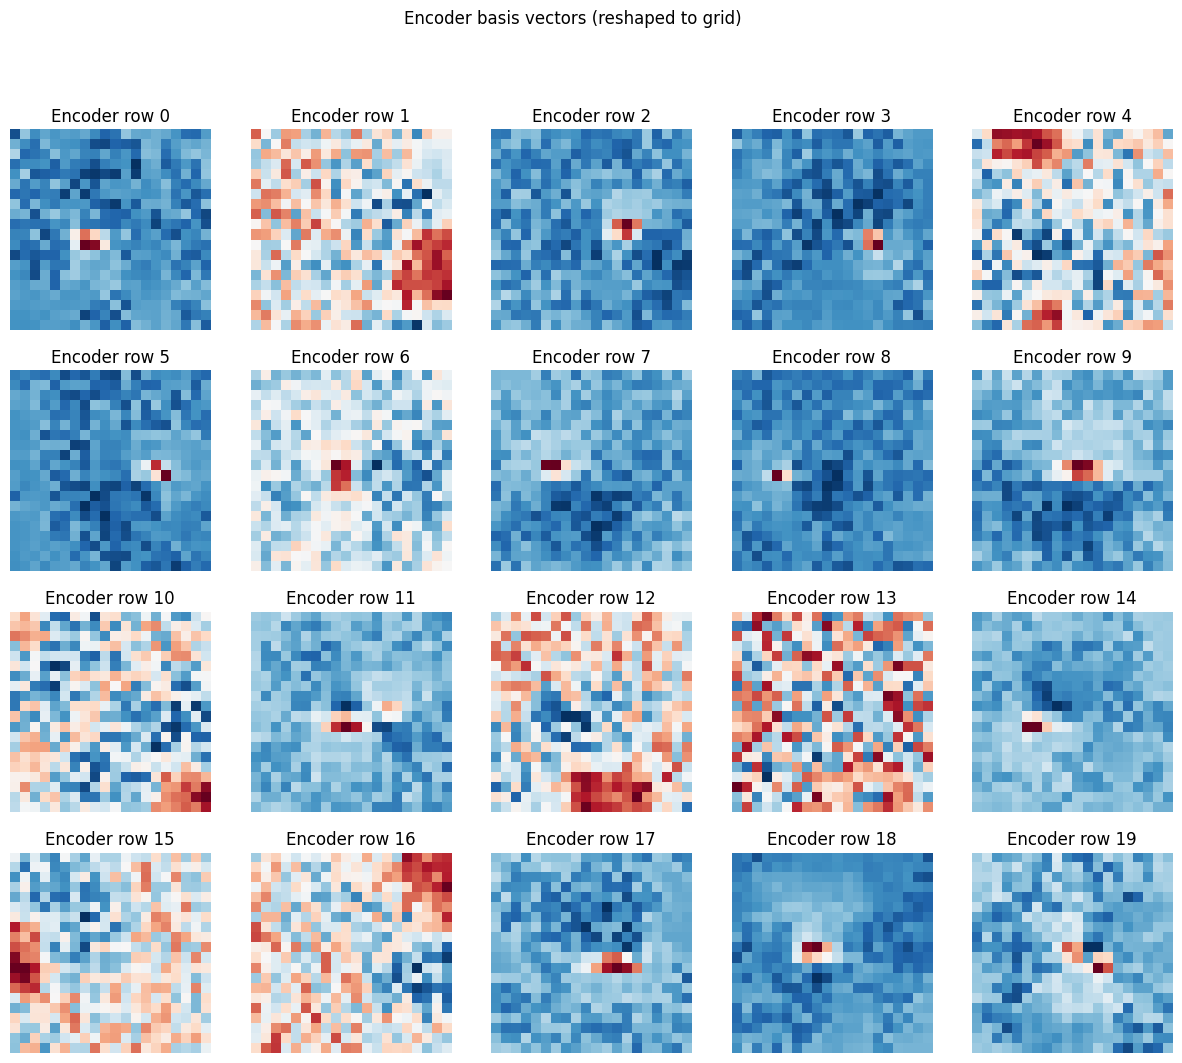

In [9]:
fig, axes = plt.subplots(4, 5, figsize=(15, 12))
for i, ax in enumerate(axes.flat):
    ax.imshow(W1[i,:].reshape(20, 20), cmap='RdBu_r')
    ax.set_title(f'Encoder row {i}')
    ax.axis('off')
plt.suptitle('Encoder basis vectors (reshaped to grid)')


Text(0.5, 0.98, 'Decoder basis vectors (reshaped to grid)')

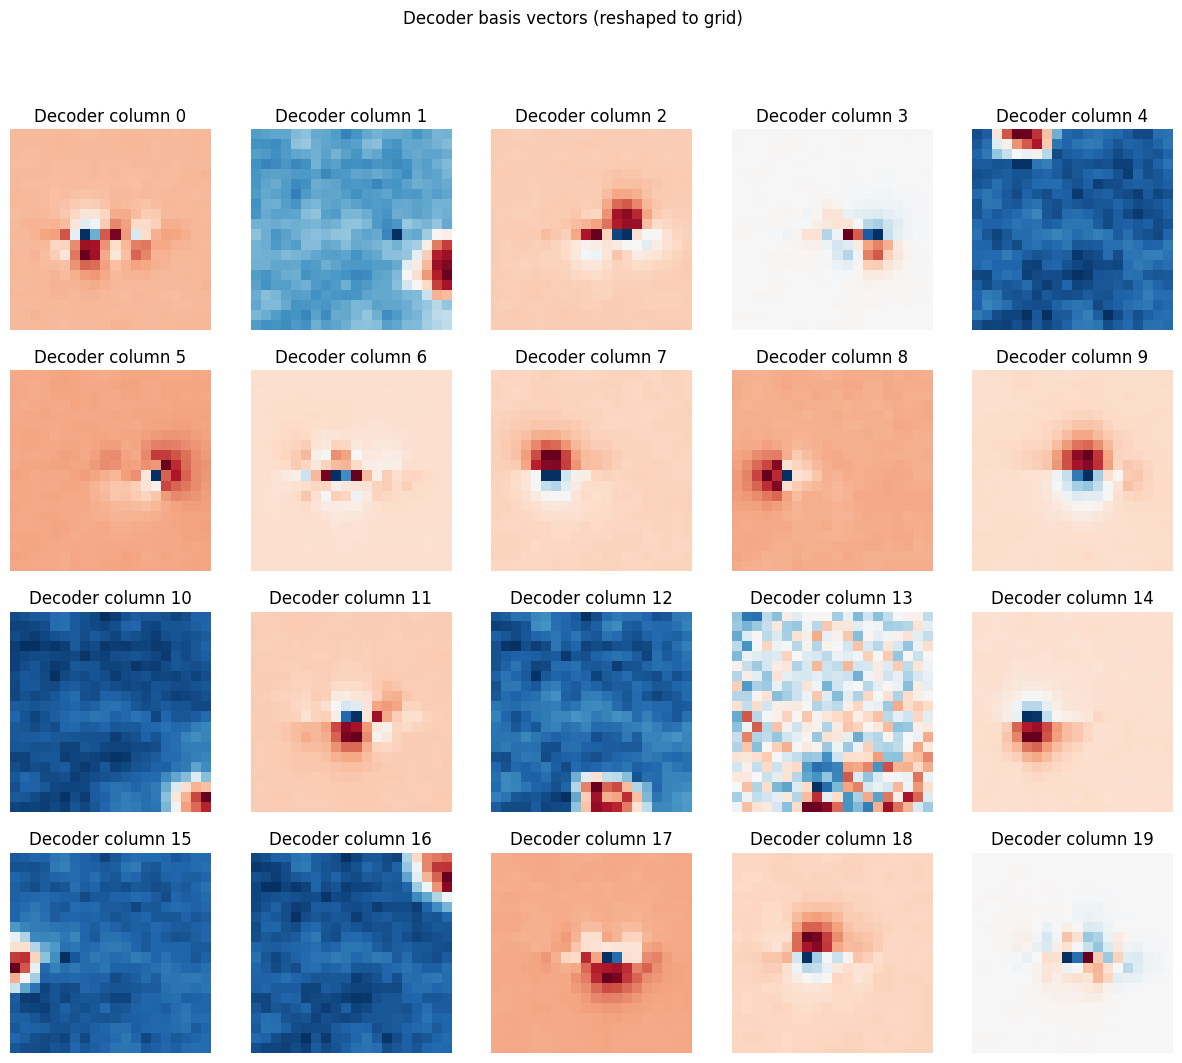

In [11]:
fig, axes = plt.subplots(4, 5, figsize=(15, 12))
for i, ax in enumerate(axes.flat):
    ax.imshow(W2[:,i].reshape(20, 20), cmap='RdBu_r')
    ax.set_title(f'Decoder column {i}')
    ax.axis('off')
plt.suptitle('Decoder basis vectors (reshaped to grid)')

### Latent activations per input
Feed a probe input into the model and inspect what the R-dim bottleneck looks like

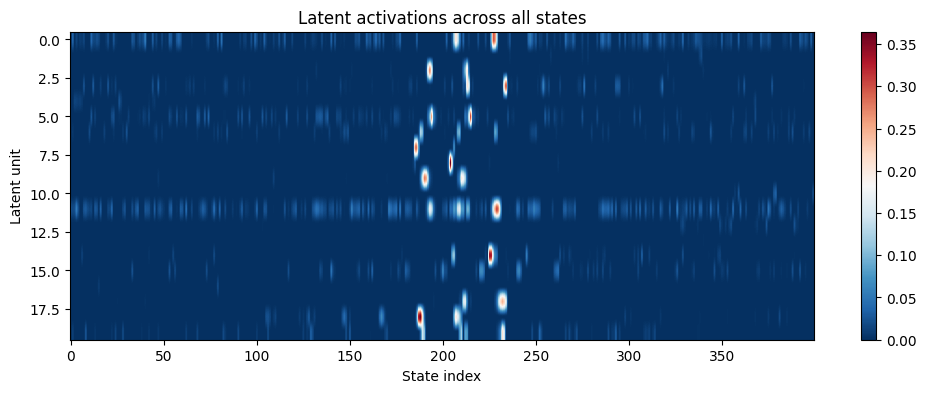

In [12]:
def get_latent(model, x):
    with torch.no_grad():
        h = torch.relu(model.repair[0](x))  # post-ReLU activations
    return h.cpu()

# Feed all one-hot state vectors
eye = torch.eye(400).to(device)
latents = get_latent(model, eye)  # (400, 20)

plt.figure(figsize=(12, 4))
plt.imshow(latents.T, aspect='auto', cmap='RdBu_r')
plt.xlabel('State index')
plt.ylabel('Latent unit')
plt.title('Latent activations across all states')
plt.colorbar()


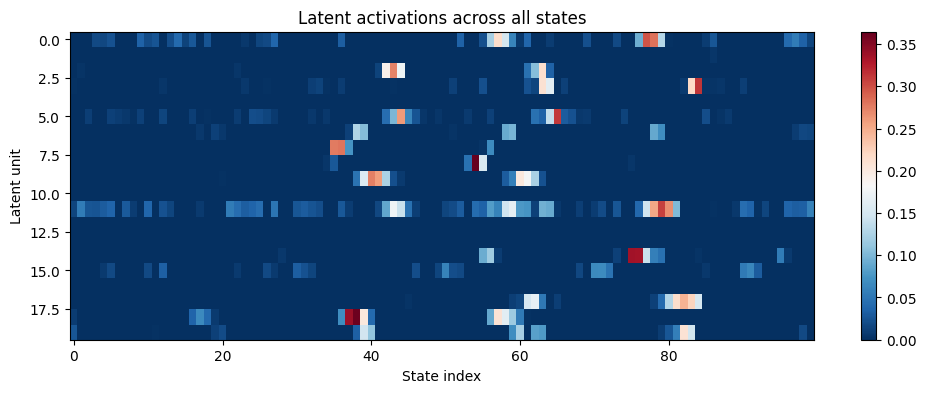

In [17]:
def get_latent(model, x):
    with torch.no_grad():
        h = torch.relu(model.repair[0](x))  # post-ReLU activations
    return h.cpu()

# Feed all one-hot state vectors
eye = torch.eye(400).to(device)
latents = get_latent(model, eye)  # (400, 20)

plt.figure(figsize=(12, 4))
plt.imshow(latents[150:250].T, aspect='auto', cmap='RdBu_r')
plt.xlabel('State index')
plt.ylabel('Latent unit')
plt.title('Latent activations across all states')
plt.colorbar()


### SVD of the weight product
The composed transform W2 @ W1 is what the network actually computes (ignoring ReLU). It's singular value tells you how much information flows through each mode

Text(0.5, 1.0, 'Effective rank of W2 @ W1')

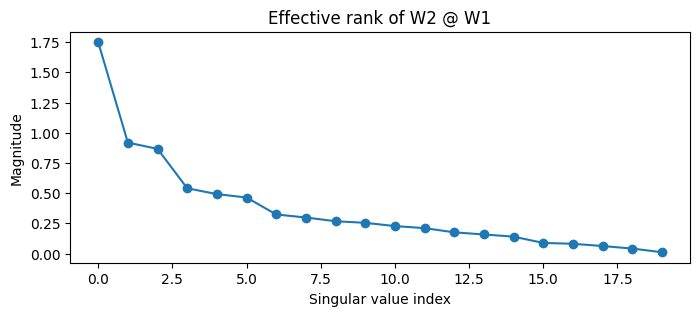

In [ ]:
M = W2 @ W1  # (400, 400) effective correction matrix
U, S, Vt = torch.linalg.svd(M)

plt.figure(figsize=(8, 3))
plt.plot(S[:30], 'o-')
plt.xlabel('Singular value index')
plt.ylabel('Magnitude')
plt.title('Effective rank of W2 @ W1')
